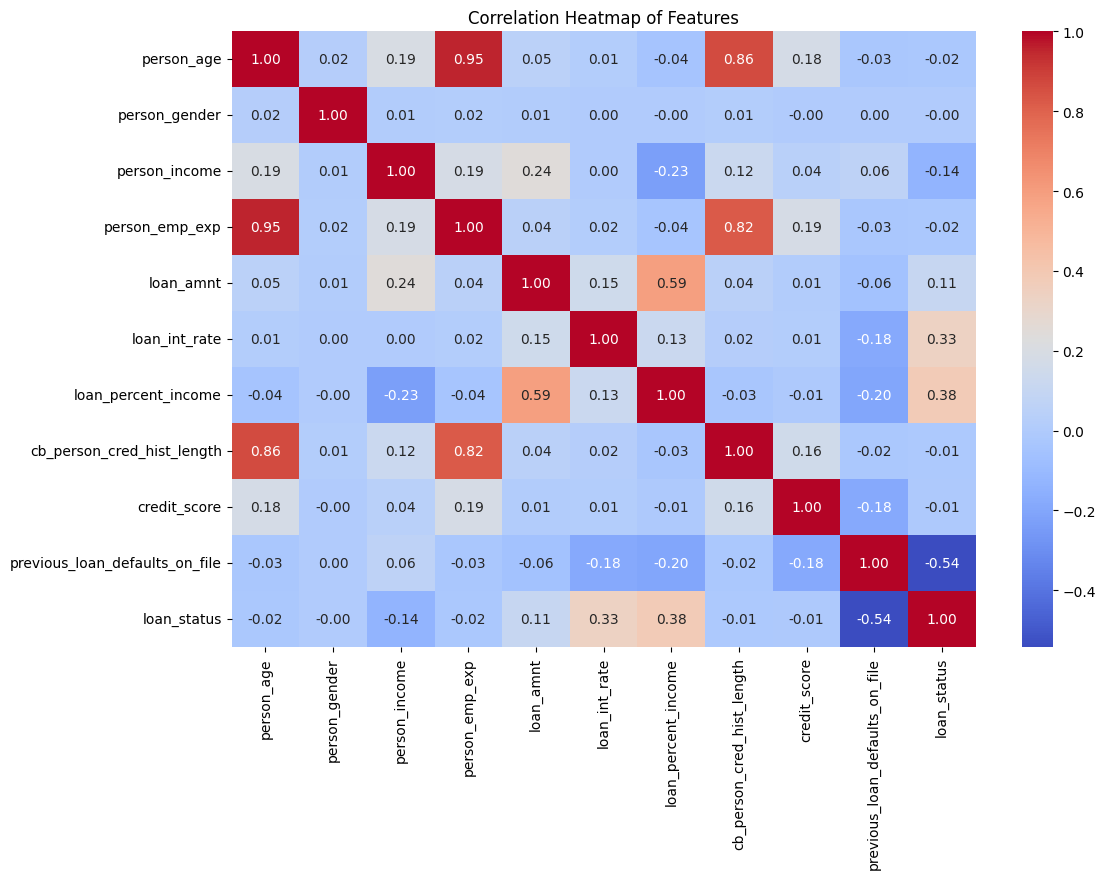

In [61]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Correlation of all the features
data = pd.read_csv('Copy of Loan Approval Dataset.csv')

# Convert categorical features to numerical for correlation analysis (if needed)

data_numeric = data.copy()
data_numeric['person_gender'] = data_numeric['person_gender'].map({'female': 0, 'male': 1})
data_numeric['previous_loan_defaults_on_file'] = data_numeric['previous_loan_defaults_on_file'].map({'No': 0, 'Yes': 1})

# Select only numerical features for correlation
numerical_features = data_numeric.select_dtypes(include=['float64', 'int64'])

# Compute correlation matrix
corr_matrix = numerical_features.corr()

# Plot heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap of Features')
plt.show()

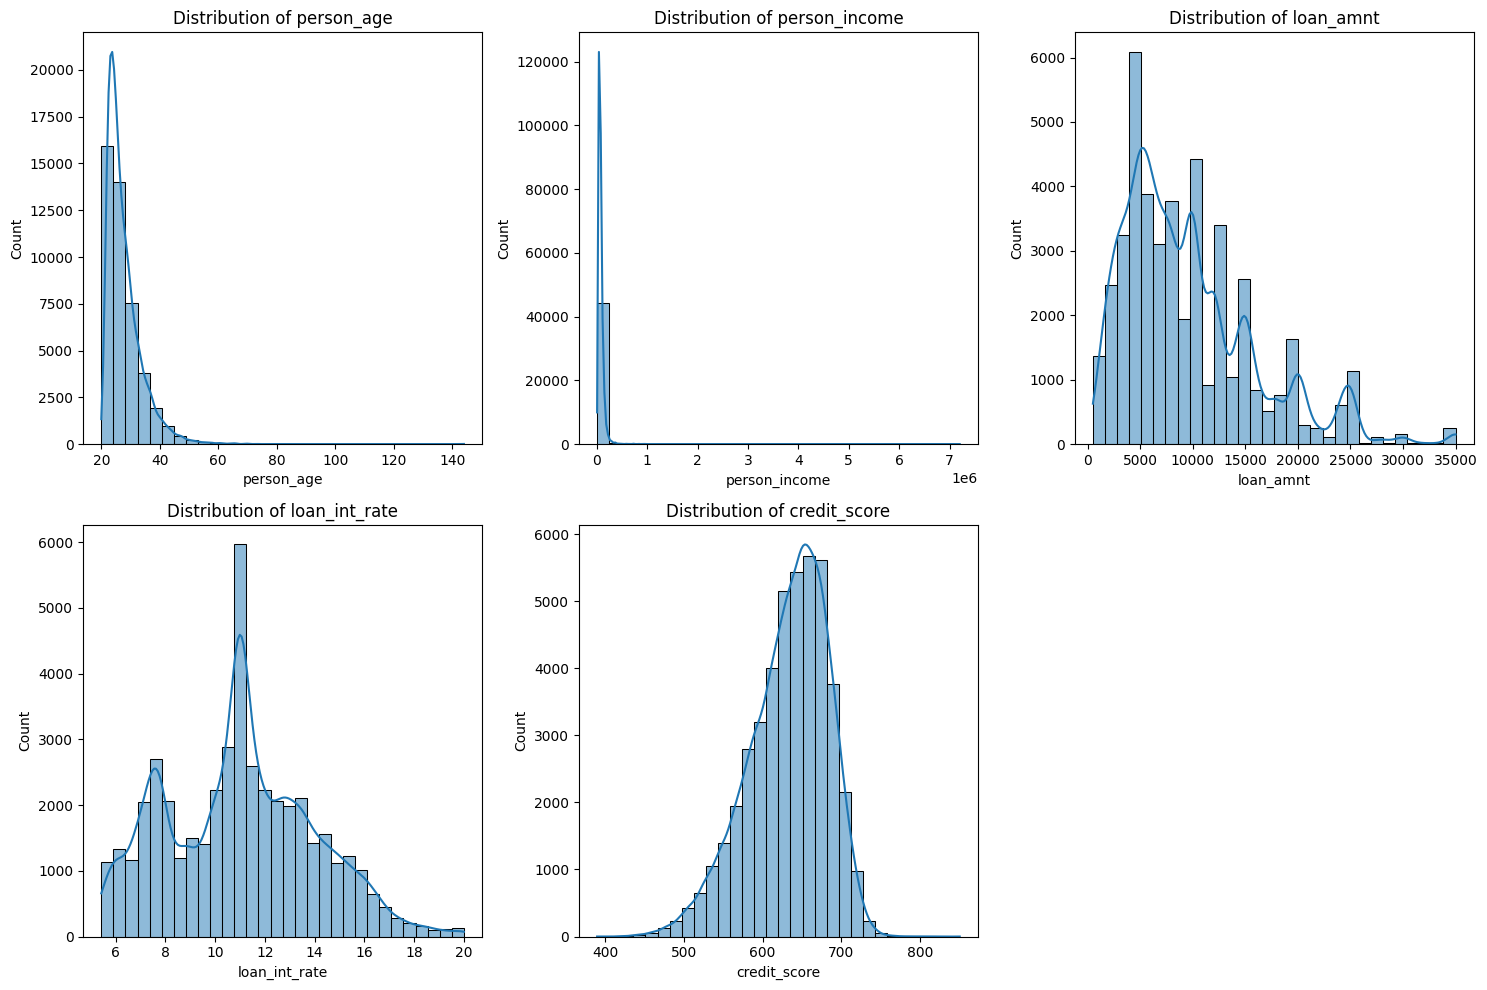

In [62]:
import seaborn as sns
import matplotlib.pyplot as plt

# Select numerical features
num_features = ['person_age', 'person_income', 'loan_amnt', 'loan_int_rate', 'credit_score']

# Plot distributions
plt.figure(figsize=(15, 10))
for i, feature in enumerate(num_features, 1):
    plt.subplot(2, 3, i)
    sns.histplot(data[feature], kde=True, bins=30)
    plt.title(f'Distribution of {feature}')
plt.tight_layout()
plt.show()

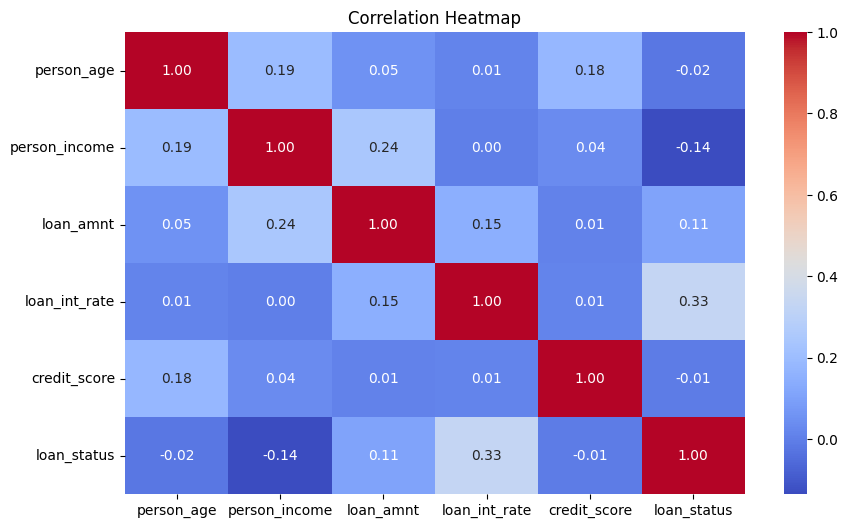

In [63]:
plt.figure(figsize=(10, 6))
sns.heatmap(data[num_features + ['loan_status']].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()


## **Dataset Pre Processing**

In [64]:

print(data.isnull().sum())
cat_features = data.select_dtypes(include=['object']).columns
print(cat_features)

from sklearn.preprocessing import LabelEncoder

education_order = ['High School', 'Associate', 'Bachelor', 'Master', 'Doctorate']
data['person_education'] = data['person_education'].map({v: k for k, v in enumerate(education_order)})

# One-Hot Encoding (Home Ownership & Loan Intent)

data = pd.get_dummies(data, columns=['person_home_ownership', 'loan_intent'], drop_first=True)

print(data.head())

print(data['person_education'].value_counts())

from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
data[['person_education']] = scaler.fit_transform(data[['person_education']])


person_age                        0
person_gender                     0
person_education                  0
person_income                     0
person_emp_exp                    0
person_home_ownership             0
loan_amnt                         0
loan_intent                       0
loan_int_rate                     0
loan_percent_income               0
cb_person_cred_hist_length        0
credit_score                      0
previous_loan_defaults_on_file    0
loan_status                       0
dtype: int64
Index(['person_gender', 'person_education', 'person_home_ownership',
       'loan_intent', 'previous_loan_defaults_on_file'],
      dtype='object')
   person_age person_gender  person_education  person_income  person_emp_exp  \
0        22.0        female                 3        71948.0               0   
1        21.0        female                 0        12282.0               0   
2        25.0        female                 0        12438.0               3   
3        23.0  

In [65]:
num_features = ['person_age', 'person_income', 'loan_amnt', 'loan_int_rate', 'credit_score']
data[num_features].describe()

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
data[num_features] = scaler.fit_transform(data[num_features])

from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
data[num_features] = scaler.fit_transform(data[num_features])

print(data[num_features].head())

from sklearn.preprocessing import RobustScaler

scaler = RobustScaler()
data[num_features] = scaler.fit_transform(data[num_features])

print(data[num_features].head())

   person_age  person_income  loan_amnt  loan_int_rate  credit_score
0    0.016129       0.008891   1.000000       0.727023      0.371739
1    0.008065       0.000595   0.014493       0.392318      0.247826
2    0.040323       0.000617   0.144928       0.510974      0.532609
3    0.024194       0.009976   1.000000       0.672840      0.619565
4    0.032258       0.008082   1.000000       0.606996      0.426087
   person_age  person_income  loan_amnt  loan_int_rate  credit_score
0   -0.666667       0.100854   3.730699       1.138636     -1.144928
1   -0.833333      -1.127215  -0.967218       0.029545     -1.971014
2   -0.166667      -1.124004  -0.345435       0.422727     -0.072464
3   -0.500000       0.261499   3.730699       0.959091      0.507246
4   -0.333333      -0.018792   3.730699       0.740909     -0.782609



# **Dataset splitting**


In [66]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, roc_auc_score

# 1. Define X and y
X = df.drop(columns=['loan_status'])
y = df['loan_status']

# 2. Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# 3. Train model
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

print(X_train.shape , y_train.shape)
print(X_test.shape , y_test.shape)



(31500, 13) (31500,)
(13500, 13) (13500,)


/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


# **Decision Tree**

Accuracy: 0.9101481481481482

Classification Report:
               precision    recall  f1-score   support

           0       0.93      0.96      0.94     10493
           1       0.84      0.73      0.78      3007

    accuracy                           0.91     13500
   macro avg       0.89      0.85      0.86     13500
weighted avg       0.91      0.91      0.91     13500

AUC Score: 0.9623


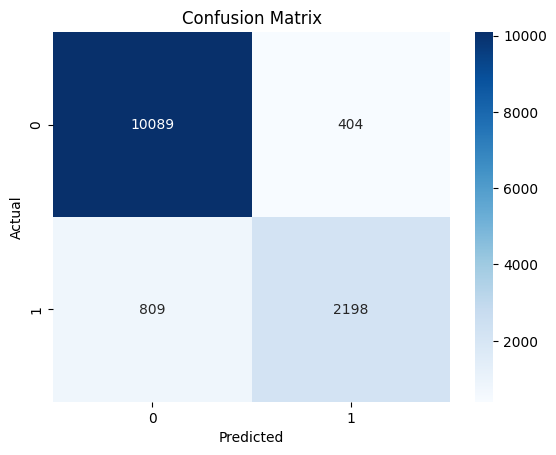

In [67]:
import pandas as pd
from sklearn.model_selection import train_test_split

# Separate features (X) and target (y)
X = df.drop(columns=['loan_status'])
y = df['loan_status']

# Split into train-test (80-20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Initialize the model (with hyperparameters to control overfitting)
dt_model = DecisionTreeClassifier(
    max_depth=5,           # Limit tree depth for simplicity
    min_samples_split=20,  # Minimum samples to split a node
    min_samples_leaf=10,   # Minimum samples in a leaf
    random_state=42
)

# Train the model
dt_model.fit(X_train, y_train)

# Predict on test set
y_pred = dt_model.predict(X_test)

# Metrics
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

print(f"AUC Score: {roc_auc:.4f}")

# Confusion Matrix
conf_matrix = confusion_matrix(y_test, y_pred)
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()


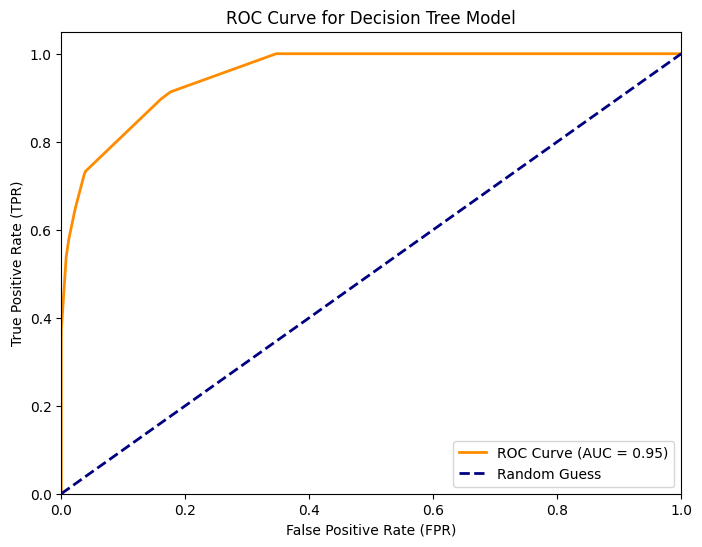

AUC Score: 0.9533


In [68]:
from sklearn.metrics import roc_curve, auc, roc_auc_score
import matplotlib.pyplot as plt

# 1. Get predicted probabilities for the positive class (loan_status=1)
y_pred_proba = dt_model.predict_proba(X_test)[:, 1]  # Probabilities for class "Approved"

# 2. Calculate ROC curve metrics
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
roc_auc = auc(fpr, tpr)  # Alternatively: roc_auc = roc_auc_score(y_test, y_pred_proba)

# 3. Plot ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC Curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Guess')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('ROC Curve for Decision Tree Model')
plt.legend(loc="lower right")
plt.show()

# 4. Print AUC score (if not using roc_auc_score earlier)
print(f"AUC Score: {roc_auc:.4f}")

# **Logistic Regression**

Accuracy: 0.8313333333333334

Classification Report:
               precision    recall  f1-score   support

           0       0.85      0.95      0.90     10493
           1       0.72      0.40      0.51      3007

    accuracy                           0.83     13500
   macro avg       0.78      0.68      0.71     13500
weighted avg       0.82      0.83      0.81     13500

ROC-AUC Score: 0.8321300617818882


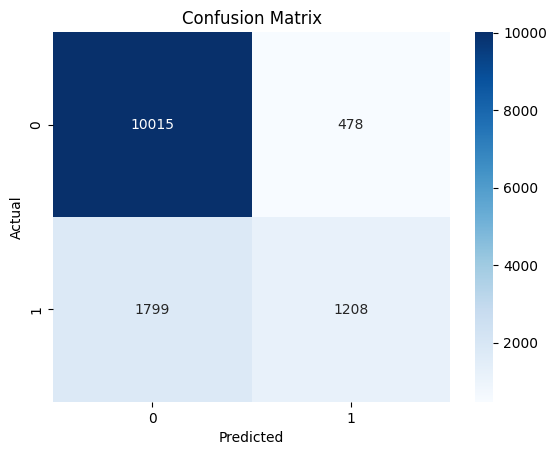

In [69]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, roc_auc_score, confusion_matrix

# Initialize the model (with L2 regularization)
logreg = LogisticRegression(
    penalty='l2',           # Regularization type (L2/Ridge)
    C=1.0,                 # Inverse of regularization strength (smaller = stronger)
    solver='liblinear',     # Solver for small datasets
    random_state=42
)

# Train the model
logreg.fit(X_train, y_train)

# Predict on test set
y_pred = logreg.predict(X_test)
y_pred_proba = logreg.predict_proba(X_test)[:, 1]

# Metrics
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))
print("ROC-AUC Score:", roc_auc_score(y_test, y_pred_proba))

# Confusion Matrix
conf_matrix = confusion_matrix(y_test, y_pred)
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

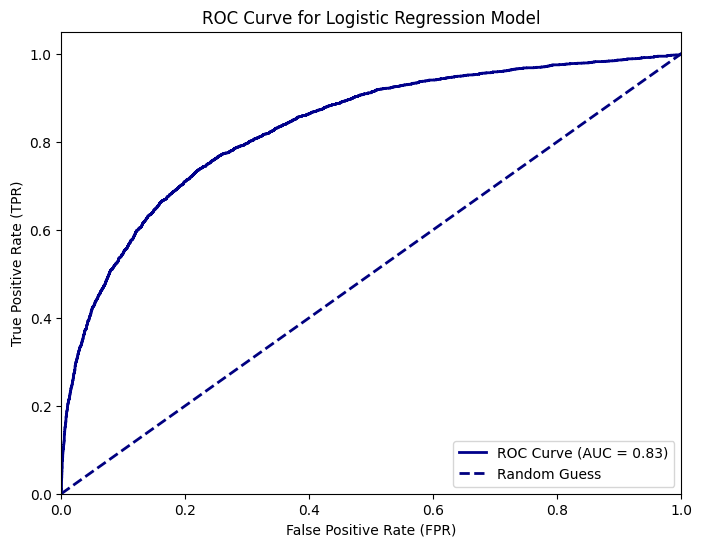

AUC Score: 0.8321


In [70]:
from sklearn.metrics import roc_curve, auc, roc_auc_score
import matplotlib.pyplot as plt

# 1. Get predicted probabilities for the positive class (loan_status=1)
y_pred_proba = logreg.predict_proba(X_test)[:, 1]  # Probabilities for class "Approved"

# 2. Calculate ROC curve metrics
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
roc_auc = auc(fpr, tpr)  # Alternatively: roc_auc = roc_auc_score(y_test, y_pred_proba)

# 3. Plot ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkblue', lw=2, label=f'ROC Curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Guess')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('ROC Curve for Logistic Regression Model')
plt.legend(loc="lower right")
plt.show()

# 4. Print AUC score
print(f"AUC Score: {roc_auc:.4f}")

# **Neural Network**

Accuracy: 0.9091111111111111

Classification Report:
               precision    recall  f1-score   support

           0       0.93      0.96      0.94     10493
           1       0.84      0.73      0.78      3007

    accuracy                           0.91     13500
   macro avg       0.88      0.84      0.86     13500
weighted avg       0.91      0.91      0.91     13500

ROC-AUC Score: 0.9623323081937439


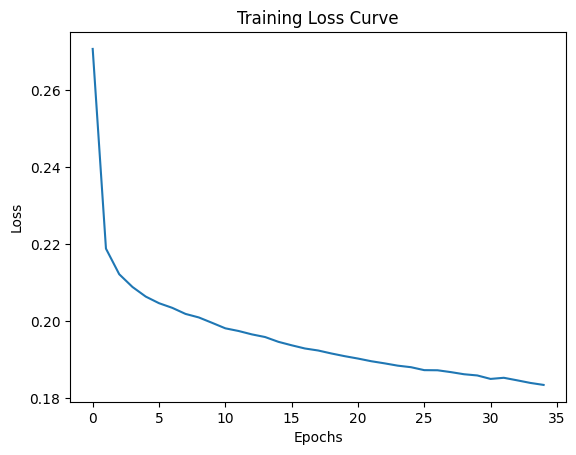

In [71]:
from sklearn.neural_network import MLPClassifier

# Initialize the model
mlp = MLPClassifier(
    hidden_layer_sizes=(64,),  # Single hidden layer with 64 neurons
    activation='relu',         # Activation function
    solver='adam',             # Optimizer
    alpha=0.001,               # L2 regularization
    batch_size=32,             # Mini-batch size
    learning_rate='adaptive',  # Adjusts learning rate
    early_stopping=True,       # Stop if validation score doesn't improve
    validation_fraction=0.1,   #of training data for validation
    random_state=42,
    max_iter=500               # Maximum epochs
)

# Train the model
mlp.fit(X_train_scaled, y_train)

from sklearn.metrics import accuracy_score, classification_report, roc_auc_score

# Predictions
y_pred = mlp.predict(X_test_scaled)
y_pred_proba = mlp.predict_proba(X_test_scaled)[:, 1]  # Probabilities for ROC-AUC

# Metrics
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))
print("ROC-AUC Score:", roc_auc_score(y_test, y_pred_proba))

import matplotlib.pyplot as plt

plt.plot(mlp.loss_curve_)
plt.title("Training Loss Curve")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.show()





# **AUC score and ROC Curve**

In [72]:
y_pred = model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))
print("ROC-AUC Score:", roc_auc_score(y_test, y_pred))

Accuracy: 0.8806666666666667

Classification Report:
               precision    recall  f1-score   support

           0       0.92      0.92      0.92     10493
           1       0.73      0.73      0.73      3007

    accuracy                           0.88     13500
   macro avg       0.83      0.83      0.83     13500
weighted avg       0.88      0.88      0.88     13500

ROC-AUC Score: 0.8265528246918123


In [73]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

y_pred_proba = logreg.predict_proba(X_test)[:, 1]  # Probabilities for class 1 (Approved)
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
roc_auc = auc(fpr, tpr)  # Area under the ROC curve

y_pred_proba = dt_model.predict_proba(X_test)[:, 1]
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
roc_auc = auc(fpr, tpr)

y_pred_proba = mlp.predict_proba(X_test_scaled)[:, 1]
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
roc_auc = auc(fpr, tpr)

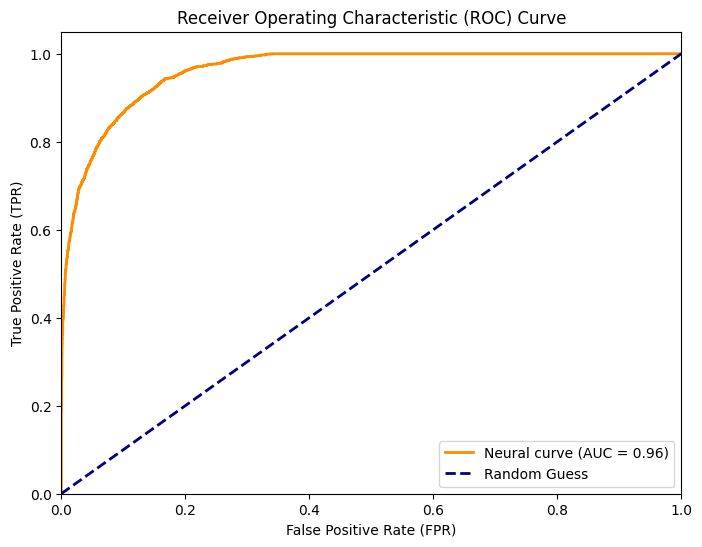

In [74]:
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'Neural curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Guess')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.show()

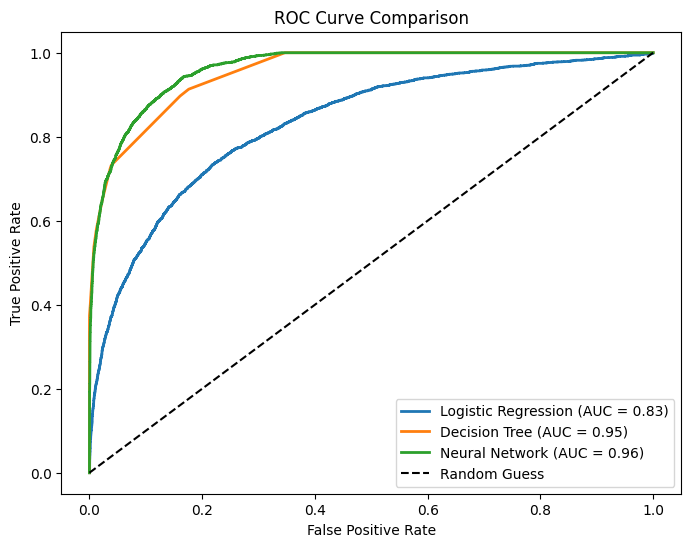

In [75]:
plt.figure(figsize=(8, 6))
models = {
    'Logistic Regression': logreg,
    'Decision Tree': dt_model,
    'Neural Network': mlp
}

for name, model in models.items():
    if name == 'Neural Network':
        y_pred_proba = model.predict_proba(X_test_scaled)[:, 1]
    else:
        y_pred_proba = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_pred_proba)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, lw=2, label=f'{name} (AUC = {roc_auc:.2f})')

plt.plot([0, 1], [0, 1], 'k--', label='Random Guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison')
plt.legend()
plt.show()